# 08busaccess: buses per hour near every hexagon (Stage 3, part 2 of 3)

For each hexagon: how many buses an hour stop within 400 m of its centre, in the **morning peak**
and as an **all-day average**, on a weekday and on a weekend day. Then the **gaps in the Rapid KL bus network**:
places where people live but Rapid KL and MRT feeder buses are rare and no rail station is within a 15-minute walk.

**Important limit:** the only open bus timetables for the Klang Valley are Prasarana's (Rapid KL and MRT feeder).
Smart Selangor's free buses and other operators (for example Wawasan Sutera in Klang, Causeway Link in Sepang)
publish no open timetables, so they are missing. Places such as Klang and Sepang have more buses than shown.
These are gaps in one network, not necessarily places without any bus.

- Input: `bus_runs.parquet`, `bus_pattern_stops.parquet`, `bus_stops.parquet` (from 07busdata),
  `hex_grid.parquet` (Stage 1), `hex_access.parquet` (Stage 2, for walking minutes to rail)
- Output: `data/processed/hex_buses.parquet`, `data/processed/bus_summary.json`, `output/stage3_frequency_preview.png`
- Next: `09buildbuses.ipynb`

**Counting rule**: a bus run counts **once** per hexagon, at the first nearby stop it reaches,
even if it passes several stops within 400 m. Both directions count, since you could board either.

## Section 0: settings

In [1]:
from pathlib import Path

BASE = Path.cwd()
PROCESSED = BASE / "data" / "processed"
OUTPUT = BASE / "output"

CATCHMENT_M = 400          # bus stops within 400 m (straight line) of the hexagon centre, a common planning rule
PEAK = (7, 9)              # morning peak: buses from 07:00 up to 09:00, averaged per hour
ALL_DAY = (6, 24)          # all-day average: buses from 06:00 up to midnight, averaged per hour
GAP_MAX_PEAK = 4           # Rapid KL gap: fewer than 4 buses an hour in the weekday peak (worse than every 15 min)
GAP_RAIL_MIN = 15          # ... and no rail station within a 15-minute walk (Stage 2)
METRIC_CRS = 32647

In [2]:
import json
import numpy as np
import pandas as pd
from pyproj import Transformer
from scipy.spatial import cKDTree

runs = pd.read_parquet(PROCESSED / "bus_runs.parquet")
pstops = pd.read_parquet(PROCESSED / "bus_pattern_stops.parquet")
stops = pd.read_parquet(PROCESSED / "bus_stops.parquet")
grid = pd.read_parquet(PROCESSED / "hex_grid.parquet")
access = pd.read_parquet(PROCESSED / "hex_access.parquet")[["h3", "rail_min"]]
print(f"{len(runs):,} runs | {pstops['pattern'].nunique():,} patterns | {len(stops):,} stops | {len(grid):,} hexagons")

16,690 runs | 1,047 patterns | 6,170 stops | 4,003 hexagons


## Step 1: bus stops within 400 m of each hexagon centre

In [3]:
to_m = Transformer.from_crs(4326, METRIC_CRS, always_xy=True)
sx, sy = to_m.transform(stops["stop_lon"].values, stops["stop_lat"].values)
hx, hy = to_m.transform(grid["lon"].values, grid["lat"].values)
near = cKDTree(np.c_[sx, sy]).query_ball_point(np.c_[hx, hy], r=CATCHMENT_M)

pairs = pd.DataFrame([(h, i) for h, idx in zip(grid["h3"], near) for i in idx], columns=["h3", "stop_row"])
pairs["feed"] = stops["feed"].values[pairs["stop_row"]]
pairs["stop_id"] = stops["stop_id"].values[pairs["stop_row"]]
grid["stops_400m"] = grid["h3"].map(pairs.groupby("h3").size()).fillna(0).astype(int)
print(f"{(grid['stops_400m'] > 0).sum():,} of {len(grid):,} hexagons have at least one bus stop within {CATCHMENT_M} m")

884 of 4,003 hexagons have at least one bus stop within 400 m


## Step 2: which buses pass nearby, and when

For each hexagon and each bus pattern that stops nearby, take the **earliest** nearby stop on that pattern.
Every run of the pattern then passes the hexagon at (run start + that offset).

In [4]:
hp = (pairs.merge(pstops, on=["feed", "stop_id"]).groupby(["h3", "pattern"], as_index=False)["offset"].min())
grid["routes_400m"] = grid["h3"].map(
    hp.merge(pstops.drop_duplicates("pattern")[["pattern"]], on="pattern").groupby("h3")["pattern"].nunique()
).fillna(0).astype(int)

passes = hp.merge(runs[["day", "pattern", "start"]], on="pattern")
passes["hour"] = (passes["start"] + passes["offset"]) / 3600
print(f"{len(passes):,} bus passes near hexagons (both days)")

def per_hour(day, window):
    a, b = window
    p = passes[(passes["day"] == day) & (passes["hour"] >= a) & (passes["hour"] < b)]
    return (p.groupby("h3").size() / (b - a))

for day in ["weekday", "weekend"]:
    grid[f"{day}_peak"] = grid["h3"].map(per_hour(day, PEAK)).fillna(0).round(1)
    grid[f"{day}_allday"] = grid["h3"].map(per_hour(day, ALL_DAY)).fillna(0).round(1)
grid[["weekday_peak", "weekday_allday", "weekend_peak", "weekend_allday"]].describe().round(1)

128,580 bus passes near hexagons (both days)


,weekday_peak,weekday_allday,weekend_peak,weekend_allday
count,4003.0,4003.0,4003.0,4003.0
mean,1.2,1.0,0.9,0.8
std,3.7,3.1,2.7,2.3
min,0.0,0.0,0.0,0.0
25%,0.0,0.0,0.0,0.0
50%,0.0,0.0,0.0,0.0
75%,0.0,0.0,0.0,0.0
max,64.5,52.5,48.5,41.3


## Step 3: gaps in the Rapid KL bus network

People live there, fewer than 4 Rapid KL or MRT feeder buses an hour pass nearby in the weekday morning peak,
and no rail station is within a 15-minute walk. (Other operators' buses are not in the data: see the note at the top.)

In [5]:
grid = grid.merge(access, on="h3", how="left")
grid["rapid_gap"] = ((grid["population"] > 0) & (grid["weekday_peak"] < GAP_MAX_PEAK) & ~(grid["rail_min"] <= GAP_RAIL_MIN))

people = grid["population"].sum()
def share(mask):
    return round(float(grid.loc[mask, "population"].sum() / people * 100), 1)

bands = [0, 0.001, 2, 4, 8, 15, 30, 1e9]
labels = ["none", "under 2", "2 to 4", "4 to 8", "8 to 15", "15 to 30", "30 or more"]
summary = {"people": int(people), "catchment_m": CATCHMENT_M, "peak": PEAK, "all_day": ALL_DAY,
           "gap_max_peak": GAP_MAX_PEAK, "gap_rail_min": GAP_RAIL_MIN,
           "operators": "Rapid KL and MRT feeder (Prasarana) only"}
for day in ["weekday", "weekend"]:
    for kind in ["peak", "allday"]:
        col = f"{day}_{kind}"
        b = pd.cut(grid[col], bands, right=False, labels=labels)
        summary[col] = {lab: share(b == lab) for lab in labels}
summary["gap_people"] = int(grid.loc[grid["rapid_gap"], "population"].sum())
summary["gap_share"] = share(grid["rapid_gap"])
summary["no_bus_people"] = int(grid.loc[(grid["population"] > 0) & (grid["stops_400m"] == 0), "population"].sum())

print("Share of people by buses per hour within 400 m, weekday morning peak:")
display(pd.Series(summary["weekday_peak"]).rename("% of people").to_frame().T)
print("Weekday all-day average:")
display(pd.Series(summary["weekday_allday"]).rename("% of people").to_frame().T)
print(f"Gaps in the Rapid KL network: {summary['gap_people']:,} people ({summary['gap_share']}%) | "
      f"no bus stop at all within {CATCHMENT_M} m: {summary['no_bus_people']:,} people")

Share of people by buses per hour within 400 m, weekday morning peak:


,none,under 2,2 to 4,4 to 8,8 to 15,15 to 30,30 or more
% of people,41.1,8.2,20.8,16.3,7.7,4.8,1.2


Weekday all-day average:


,none,under 2,2 to 4,4 to 8,8 to 15,15 to 30,30 or more
% of people,41.1,16.7,17.1,14.5,6.4,4.0,0.3


Gaps in the Rapid KL network: 5,160,222 people (61.8%) | no bus stop at all within 400 m: 3,419,111 people


In [6]:
# By district: people-weighted average buses per hour, and people in Rapid KL gaps
def wavg(d, col):
    return np.average(d[col], weights=d["population"]) if d["population"].sum() > 0 else np.nan

by_district = grid.groupby("district").apply(lambda d: pd.Series({
    "weekday peak": round(wavg(d, "weekday_peak"), 1),
    "weekday all-day": round(wavg(d, "weekday_allday"), 1),
    "weekend all-day": round(wavg(d, "weekend_allday"), 1),
    "people in Rapid KL gaps": int(d.loc[d["rapid_gap"], "population"].sum()),
    "% in gaps": round(d.loc[d["rapid_gap"], "population"].sum() / d["population"].sum() * 100, 1),
}))
summary["by_district"] = by_district.reset_index().to_dict(orient="records")
by_district.sort_values("weekday peak", ascending=False)

,weekday peak,weekday all-day,weekend all-day,people in Rapid KL gaps,% in gaps
district,,,,,
W.P. Kuala Lumpur,6.7,5.5,4.2,679124.0,35.9
Ulu Langat,4.7,3.7,3.0,910957.0,62.2
Petaling,3.4,3.0,2.4,1585428.0,60.8
W.P. Putrajaya,3.0,1.6,1.0,7353.0,85.6
Gombak,2.5,2.3,2.0,587959.0,68.2
Sepang,0.5,0.4,0.3,372910.0,93.4
Klang,0.4,0.4,0.3,1016491.0,91.7


## Step 4: save

In [7]:
cols = ["h3", "district", "lat", "lon", "population", "stops_400m", "routes_400m",
        "weekday_peak", "weekday_allday", "weekend_peak", "weekend_allday", "rail_min", "rapid_gap"]
grid[cols].to_parquet(PROCESSED / "hex_buses.parquet", index=False)
(PROCESSED / "bus_summary.json").write_text(json.dumps(summary, indent=1, default=str))
print("Saved hex_buses.parquet and bus_summary.json")

Saved hex_buses.parquet and bus_summary.json


## Step 5: flat preview

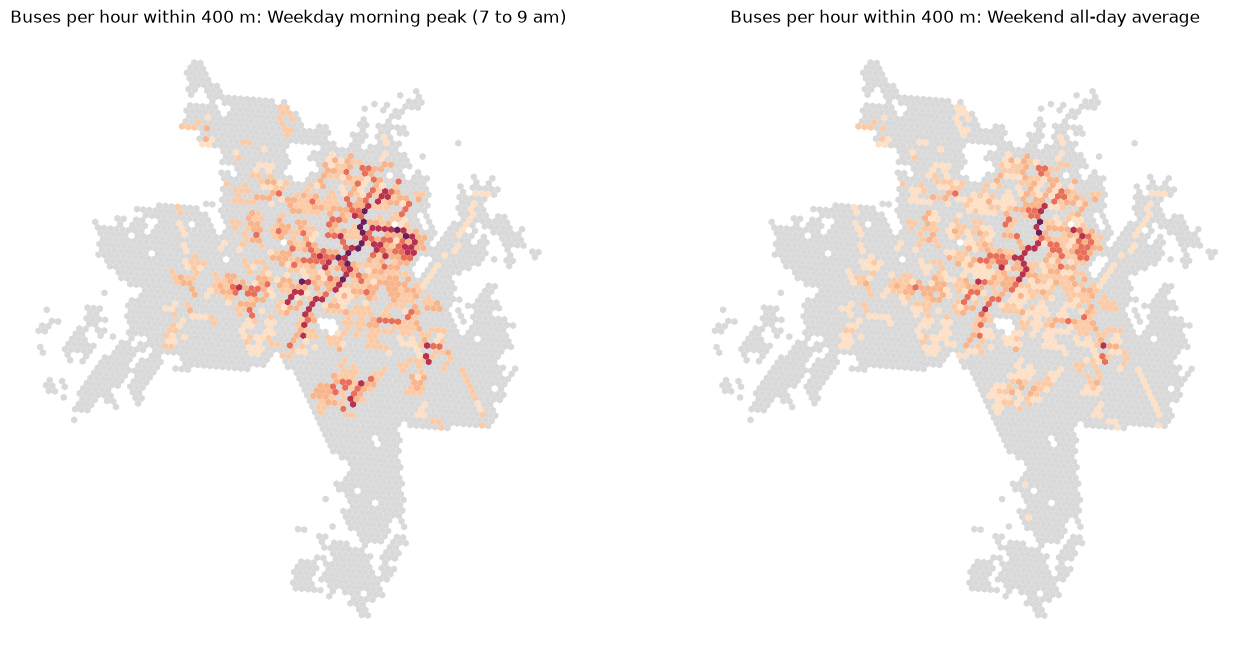

In [8]:
import h3
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from shapely.geometry import Polygon

shapes = grid["h3"].map(lambda c: Polygon([(lon, lat) for lat, lon in h3.cell_to_boundary(c)]))
g = gpd.GeoDataFrame(grid, geometry=list(shapes), crs=4326)
g = g[g["population"] > 0]
cmap = ListedColormap(["#d9d9d9", "#fde0c5", "#facba6", "#f8b58b", "#e8705a", "#b8324f", "#6b1e5a"])
norm = BoundaryNorm(bands, cmap.N)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, col, title in [(axes[0], "weekday_peak", "Weekday morning peak (7 to 9 am)"),
                       (axes[1], "weekend_allday", "Weekend all-day average")]:
    g.plot(ax=ax, column=col, cmap=cmap, norm=norm)
    ax.set_title(f"Buses per hour within {CATCHMENT_M} m: {title}"); ax.set_axis_off()
plt.savefig(OUTPUT / "stage3_frequency_preview.png", dpi=90, bbox_inches="tight")
plt.show()

___
**END**